# Logistics Delivery Time Prediction and Optimization
### Week 4: Predictive Modeling and Optimization

**Dataset:** Delivery_Logistics_Cleaned.csv (25,000 deliveries, 14 columns), the cleaned data from Week 2
**Problem:** Predict how many hours a delivery will take, then use the model to improve delivery promises and planning.

## Step 1: Define the Problem and Prepare the Data

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("D:\\PROJECT\\Yuva Intern\\Dataset\\Delivery_Logistics_Cleaned.csv")

# What we want to predict
target = "delivery_time_hours"

# What we use to predict it
features = ["distance_km", "package_weight_kg", "delivery_mode",
            "weather_condition", "vehicle_type", "region",
            "delivery_partner", "package_type"]

# Turn text columns into 0/1 columns so the models can use them
X = pd.get_dummies(df[features], drop_first=True)
y = df[target]

# Keep 20% of the data aside to test the model later
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of input columns:", X_train.shape[1])

Training rows: 20000
Testing rows: 5000
Number of input columns: 35


## Data Preparation Result

| Item | Choice |
|---|---|
| Target (what we predict) | delivery_time_hours |
| Features (what we use) | distance, weight, delivery mode, weather, vehicle type, region, partner, package type |
| Left out on purpose | expected time, delayed, delivery status, rating, cost |
| Training rows | 20,000 (80%) |
| Testing rows | 5,000 (20%) |
| Input columns after encoding | 35 |

**Why these choices:**
- Text columns were turned into 0/1 columns, because models only understand numbers.
- Expected time is the promise itself, and delayed, status and rating only exist after the delivery. Using them would let the model "cheat" with information that is not available when a delivery is planned.
- Cost was left out because it is almost fully decided by distance (0.99), so it adds nothing new.
- 20% of the data was kept hidden, so the model is tested on deliveries it has never seen. This shows how it would perform on future deliveries.

## Step 2: Train and Compare Models

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Baseline (always the average)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions),
    })

print(pd.DataFrame(results).round(2))

                           Model   MAE  RMSE    R2
0  Baseline (always the average)  2.51  3.11 -0.00
1              Linear Regression  1.28  1.62  0.73
2                  Decision Tree  1.30  1.65  0.72
3                  Random Forest  1.29  1.63  0.72


## Model Comparison Result

| Model | MAE (hours) | RMSE (hours) | R2 |
|---|---|---|---|
| Baseline (always the average) | 2.51 | 3.11 | -0.00 |
| Linear Regression | 1.28 | 1.62 | 0.73 |
| Decision Tree | 1.30 | 1.65 | 0.72 |
| Random Forest | 1.29 | 1.63 | 0.72 |

**Insight:**
- The baseline is wrong by 2.51 hours on average. Linear regression cuts this to 1.28 hours, about 49% lower, and explains 73% of the variation in delivery time (R2 = 0.73).
- The three models are almost identical (MAE between 1.28 and 1.30). The more complex models, the decision tree and the random forest, did not beat the simple linear regression.
- A likely reason is that delivery time depends mostly on distance in a straight-line way (correlation 0.69 in Week 3), which a linear model captures well. Complex models only help when relationships are complicated, and here they are not.
- Linear regression is therefore the best choice: it is as accurate as the others, faster to run, and easier to explain to a manager.
- About 27% of the variation is still unexplained. The dataset has no information on things such as traffic, loading time, or driver, and these likely explain the rest.

**What this means for operations:** a typical prediction is off by about 1.3 hours, which is small compared with the 6.2 hour average delivery. The model is accurate enough to be used for setting promised times, but not to promise delivery to the exact hour.

## Step 3: Cross-Validation

In [4]:
from sklearn.model_selection import cross_validate

for name in ["Linear Regression", "Decision Tree", "Random Forest"]:
    cv = cross_validate(models[name], X, y, cv=5,
                        scoring=["r2", "neg_mean_absolute_error"])
    r2 = cv["test_r2"]
    mae = -cv["test_neg_mean_absolute_error"]
    print(name)
    print("  R2 :", round(r2.mean(), 3), "(spread:", round(r2.std(), 3), ")")
    print("  MAE:", round(mae.mean(), 2), "hours")
    print()

Linear Regression
  R2 : 0.735 (spread: 0.005 )
  MAE: 1.28 hours

Decision Tree
  R2 : 0.726 (spread: 0.006 )
  MAE: 1.3 hours

Random Forest
  R2 : 0.728 (spread: 0.005 )
  MAE: 1.3 hours



## Cross-Validation Result

| Model | Average R2 | Spread of R2 | Average MAE (hours) |
|---|---|---|---|
| Linear Regression | 0.735 | 0.005 | 1.28 |
| Decision Tree | 0.726 | 0.006 | 1.30 |
| Random Forest | 0.728 | 0.005 | 1.30 |

**Insight:**
- The cross-validation results (R2 0.726 to 0.735) are almost the same as the single test results (0.72 to 0.73). The first test was not a lucky split.
- The spread is only 0.005 to 0.006, so the models perform almost the same on every part of the data. This means predictions would be reliable on new deliveries.
- Linear regression is again slightly the best (R2 0.735, MAE 1.28 hours), so the conclusion does not change.
- The differences between the models (about 0.01 in R2) are smaller than what most businesses would notice. Model choice matters less here than the quality of the information the model is given.

## Step 4: Hyperparameter Tuning

In [5]:
from sklearn.model_selection import GridSearchCV

settings = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [10, 50, 100],
}

search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    settings,
    cv=5,
    scoring="r2",
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Best cross-validation R2:", round(search.best_score_, 3))

# Test the tuned model on the hidden 20%
best_tree = search.best_estimator_
predictions = best_tree.predict(X_test)
print("Test MAE :", round(mean_absolute_error(y_test, predictions), 2), "hours")
print("Test RMSE:", round(mean_squared_error(y_test, predictions) ** 0.5, 2), "hours")
print("Test R2  :", round(r2_score(y_test, predictions), 3))

Best settings: {'max_depth': 7, 'min_samples_leaf': 100}
Best cross-validation R2: 0.732
Test MAE : 1.29 hours
Test RMSE: 1.63 hours
Test R2  : 0.724


## Hyperparameter Tuning Result

| Item | Decision tree before tuning | Decision tree after tuning |
|---|---|---|
| Settings | max_depth 6 | max_depth 7, min_samples_leaf 100 |
| Test MAE (hours) | 1.30 | 1.29 |
| Test RMSE (hours) | 1.65 | 1.63 |
| Test R2 | 0.72 | 0.724 |

**Best cross-validation R2:** 0.732 (12 setting combinations tested with 5-fold cross-validation).

**Insight:**
- Tuning improved the decision tree by only 0.01 hours of MAE and 0.02 hours of RMSE. The tuned tree (MAE 1.29) is still no better than the simple linear regression (MAE 1.28).
- The result is consistent: three different models, with and without tuning, all end at an R2 of about 0.72 to 0.73. This points to a limit in the information, not in the models. The dataset does not include factors such as traffic, loading time or the driver, so no model can do much better with these inputs.
- For a company, this means that collecting new data (for example traffic and loading time) is likely to improve predictions more than building more complex models.

## Step 5: What Drives Delivery Time?

distance_km                 0.611
weather_condition_stormy    0.170
weather_condition_rainy     0.113
weather_condition_foggy     0.045
package_weight_kg           0.021
package_type_pharmacy       0.002
region_north                0.002
delivery_mode_same day      0.002
dtype: float64


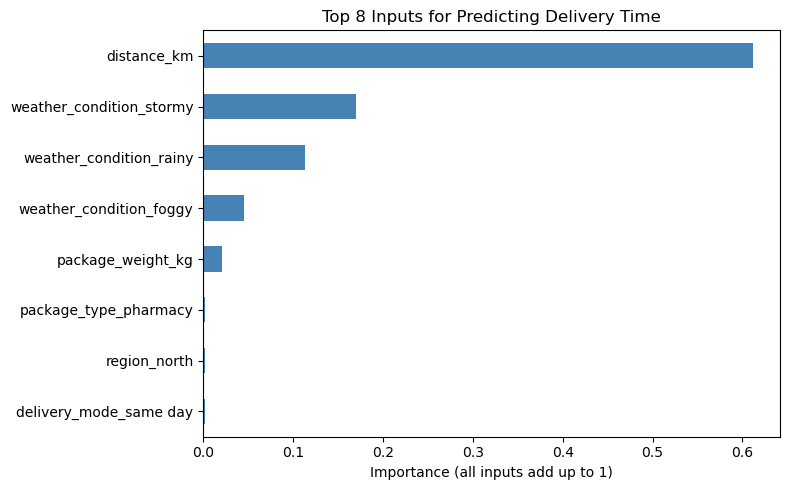

In [6]:
import matplotlib.pyplot as plt

rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importance.head(8).round(3))

importance.head(8).sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Top 8 Inputs for Predicting Delivery Time")
plt.xlabel("Importance (all inputs add up to 1)")
plt.tight_layout()

plt.show()

## Feature Importance Result

**Why this chart:** A horizontal bar chart sorted from largest to smallest shows at a glance which inputs the model relied on, and long input names stay readable.

| Input | Importance (approx.) | Meaning |
|---|---|---|
| distance_km | 0.61 | By far the most useful input |
| weather_condition_stormy | 0.17 | Storms add time |
| weather_condition_rainy | 0.11 | Rain adds time |
| weather_condition_foggy | 0.05 | Fog adds some time |
| package_weight_kg | 0.02 | Small effect |
| package_type_pharmacy, region_north, delivery_mode_same day | close to 0 | Almost no effect |

**Insight:**
- Distance and the three bad-weather conditions together make up about 94% of the model's importance. Delivery time is therefore explained mainly by how far the package travels and whether the weather is bad.
- Delivery mode, vehicle type, partner and region have almost no importance. This fits what Week 3 showed: all four delivery modes take about 6.2 hours, so the mode is a promise and not a different speed of delivery.
- Stormy weather (0.17) matters more than rainy (0.11), which matters more than foggy (0.05). This is the same order as the delay rates in Week 3 (41.4%, 37.4% and 30.3%), which supports the finding from a second angle.
- Weight has a small importance (0.02) even though its correlation with time was 0.00. A likely reason is that weight matters only in some conditions, though this was not tested.

**What this means for operations:** planning time should be based on distance and the weather forecast. These two inputs are known before a delivery starts, so they can be used to give each customer a realistic promise.

## Step 6: Optimization, Data-Driven Delivery Promises

In [7]:
# Use the best model (linear regression)
lin = models["Linear Regression"]

# Find the safety buffer: how many extra hours cover 90% of the mistakes
train_errors = y_train - lin.predict(X_train)
buffer = train_errors.quantile(0.90)
print("Safety buffer:", round(buffer, 2), "hours")

# Build the new promises for the test deliveries
test = df.loc[y_test.index].copy()
test["predicted"] = lin.predict(X_test)
test["new_promise"] = test["predicted"] + buffer

# Was each delivery on time under the current and the new promise?
test["on_time_now"] = test["delivery_time_hours"] <= test["expected_time_hours"]
test["on_time_new"] = test["delivery_time_hours"] <= test["new_promise"]

summary = test.groupby("delivery_mode")[
    ["expected_time_hours", "new_promise", "on_time_now", "on_time_new"]
].mean()
summary["on_time_now"] = summary["on_time_now"] * 100
summary["on_time_new"] = summary["on_time_new"] * 100

print(summary.round(1))
print()
print("Overall on-time now:", round(test["on_time_now"].mean() * 100, 1), "%")
print("Overall on-time new:", round(test["on_time_new"].mean() * 100, 1), "%")

Safety buffer: 2.07 hours
               expected_time_hours  new_promise  on_time_now  on_time_new
delivery_mode                                                            
express                        4.5          8.3         35.8         88.3
same day                       8.0          8.2         78.1         91.2
standard                      24.0          8.3        100.0         90.3
two day                       16.0          8.3         99.9         89.5

Overall on-time now: 78.2 %
Overall on-time new: 89.8 %


## Optimization Result: Data-Driven Delivery Promises

**Method:** New promise = predicted delivery time (linear regression) + a safety buffer of 2.07 hours. The buffer is the 90th percentile of the model's mistakes on the training data, so the promise should be met about 90% of the time. On-time here means actual time is less than or equal to the promised time.

| Delivery mode | Current promise (hours) | New promise (hours) | On time now | On time with new promise |
|---|---|---|---|---|
| Express | 4.5 | 8.3 | 35.8% | 88.3% |
| Same day | 8.0 | 8.2 | 78.1% | 91.2% |
| Standard | 24.0 | 8.3 | 100.0% | 90.3% |
| Two day | 16.0 | 8.3 | 99.9% | 89.5% |
| **Overall** | | | **78.2%** | **89.8%** |

**Insight:**
- Express improves the most: on-time delivery rises from 35.8% to 88.3% (+52.5 points) when the promise moves from 4.5 to 8.3 hours. Same day also improves, from 78.1% to 91.2%.
- Overall on-time delivery rises by 11.6 points (78.2% to 89.8%), and the result is close to the 90% target on test data the model had never seen, so the buffer works on new deliveries.
- There is a trade-off for standard and two day. Their current promises (24 and 16 hours) are far longer than needed, so they are on time 100% and 99.9% of the time, but they would drop to 90.3% and 89.5% if shortened to 8.3 hours. Shorter promises are more attractive to customers but accept about 1 late delivery in 10.
- The new promises are almost the same for all four modes (8.2 to 8.3 hours). This confirms that the modes do not differ in real delivery speed, only in what is promised.

**What this means for operations:**
- If the company keeps the four delivery modes, it should either make express truly faster (priority handling, fewer stops) or stop promising 4.5 hours.
- Standard and two day can promise much less than 24 and 16 hours, if the company accepts a small late rate or uses a larger buffer for those modes.
- Promises should change with distance and weather, since these are the main drivers of delivery time (Step 5).

## Step 7: What Each Factor Adds to Delivery Time

In [8]:
coef = pd.Series(lin.coef_, index=X.columns)

print("Extra hours per additional 100 km:", round(coef["distance_km"] * 100, 2))
print()

weather_cols = [c for c in X.columns if c.startswith("weather_condition_")]
print("Extra hours compared with clear weather:")
print(coef[weather_cols].sort_values(ascending=False).round(2))

Extra hours per additional 100 km: 2.5

Extra hours compared with clear weather:
weather_condition_stormy    4.08
weather_condition_rainy     3.05
weather_condition_foggy     1.72
weather_condition_hot       0.02
weather_condition_cold      0.00
dtype: float64


## Factor Effects Result

| Factor | Extra delivery time | Compared with |
|---|---|---|
| Each additional 100 km | +2.50 hours | Every 100 km adds the same time |
| Stormy weather | +4.08 hours | Clear weather |
| Rainy weather | +3.05 hours | Clear weather |
| Foggy weather | +1.72 hours | Clear weather |
| Hot weather | +0.02 hours | Clear weather |
| Cold weather | +0.00 hours | Clear weather |

**Insight:**
- Every 100 km adds 2.5 hours. A storm adds 4.08 hours, which is the same as driving about 163 extra km (4.08 ÷ 2.5 × 100). Rain adds 3.05 hours (about 122 km) and fog adds 1.72 hours (about 69 km).
- Compared with the average delivery time of 6.2 hours, a storm adds about 66% more time, which explains why express and same day deliveries fail so often in storms.
- Hot and cold weather add almost nothing (0.02 and 0.00 hours), so temperature is not the problem. The problem is wet roads and poor visibility, as seen in Week 3.
- This model assumes weather adds the same hours to every delivery. In real operations a storm may add more time on long trips, but this was not tested here.

**What this means for operations:**
- Planners can use these numbers directly: on a stormy day, add about 4 hours to every promise, about 3 hours on a rainy day, and about 1.7 hours on a foggy day.
- A route that is 100 km shorter saves about 2.5 hours, which is more than the time saved by avoiding fog. Route planning that shortens distances therefore has the largest effect on delivery time.
- Stormy and rainy days need extra vehicles or earlier dispatch, because each delivery will occupy a driver for 3 to 4 hours longer than usual.